# 05 · Eksplorasi hubungan perangkat–tujuan yang diterbitkan

Untuk cerita final kunjungan siang, gunakan [notebook 07](07_daytime_visit_pairs.ipynb).
Notebook ini memakai ukuran lain: porsi hubungan perangkat–tujuan terbit yang menuju Kota,
bukan jumlah pengunjung unik atau persentase penduduk. Satu perangkat dapat menyumbang
beberapa hubungan tujuan. Normalisasi tidak menghilangkan bias sampel atau suppression.

Data Desember 2021–Februari 2022; perangkat dengan perkiraan rumah di asal teramati pada
08.00–17.59 di tujuan setidaknya sekali dalam bulan itu. Sekali atau berkali-kali tetap satu
perangkat pada pasangan-bulan. Maret–April dikeluarkan karena kualitas OD rendah.

`city_rate` adalah jumlah hubungan Kota terbit / perangkat rumah asal. `city_share` adalah
hubungan Kota terbit / seluruh hubungan terbit di luar asal. Nilai Kota yang tidak terbit
seluruhnya tetap tidak diketahui, bukan nol. Perbandingan rata-rata hanya memakai asal atau
pasangan yang tersedia pada seluruh tiga bulan. Sel kosong pada heatmap berarti tidak lengkap.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import CITY_KAB_CODE as CITY, FIGURES as FIG, KAB_ORDER, N_KAPANEWON, OD_GOOD_MONTHS, PROCESSED
from applied import MIN_HOMED, city_visits, ranked_origins, complete_pair_rates

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 30)
JP_COL = "#0F766E"            # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)         # 1920 x 1080 at 150 dpi
KAB_COL = dict(zip(KAB_ORDER, sns.color_palette("Set2", len(KAB_ORDER))))

od = pd.read_parquet(PROCESSED / "od_dec_feb.parquet")
od["month"] = od.month.astype(str)
assert sorted(od.month.unique()) == OD_GOOD_MONTHS
assert od.origin_code.nunique() == N_KAPANEWON
assert not od.duplicated(["month", "origin_code", "dest_code"]).any()
names = od.drop_duplicates("origin_code").set_index("origin_code")[["origin_kab_kota", "origin_kapanewon"]]
names.columns = ["kab_kota", "kapanewon"]

def savefig(fig, name):
    fig.savefig(FIG / f"visits_{name}.png")

print(f"{len(od):,} origin-destination-month rows, {od.origin_code.nunique()} origins, months {OD_GOOD_MONTHS}")

7,872 origin-destination-month rows, 78 origins, months ['2021-12', '2022-01', '2022-02']


## 1. City visit rate and city share per origin and month

In [2]:
homed = od.drop_duplicates(["month", "origin_code"]).pivot(index="origin_code", columns="month",
                                                           values="n_homed_maids")
away = od[~od.is_intra]
cv = city_visits(od)
city_rate = cv.city_rate.unstack()
city_share = cv.city_share.unstack()
print("Home devices per origin and month:")
display(homed.describe().round(0))
ranked = ranked_origins(od)
print(f"Origins with >= {MIN_HOMED} home devices in every month: {len(ranked)} of {len(homed)}")
print("Left out:", ", ".join(names.loc[homed.index.difference(ranked), "kapanewon"].str.title()))

outside = ranked[names.loc[ranked, "kab_kota"] != "YOGYAKARTA"]
print("\nMonth-to-month Spearman of city share, origins outside the city:")
display(city_share.loc[outside].corr(method="spearman").round(2))
print("Median city visit rate by month, origins outside the city (rises as the panel changes):")
print(city_rate.loc[outside].median().round(3).to_dict())

Home devices per origin and month:


month,2021-12,2022-01,2022-02
count,78.0,78.0,78.0
mean,1566.0,1103.0,996.0
std,2082.0,1425.0,1368.0
min,26.0,48.0,30.0
25%,332.0,233.0,180.0
50%,809.0,598.0,436.0
75%,1633.0,1269.0,1100.0
max,9495.0,8217.0,7336.0


Origins with >= 100 home devices in every month: 65 of 78
Left out: Patuk, Paliyan, Panggang, Tepus, Rongkop, Ngawen, Saptosari, Girisubo, Tanjungsari, Purwosari, Gedongtengen, Ngampilan, Wirobrajan

Month-to-month Spearman of city share, origins outside the city:


month,2021-12,2022-01,2022-02
month,,,
2021-12,1.00,0.55,0.40
2022-01,0.55,1.00,0.82
2022-02,0.40,0.82,1.00


Median city visit rate by month, origins outside the city (rises as the panel changes):
{'2021-12': 0.094, '2022-01': 0.142, '2022-02': 0.19}


## 2. Origins outside the city

In [3]:
res = pd.DataFrame({
    "city share (%)": city_share.loc[outside].reindex(columns=OD_GOOD_MONTHS).mean(axis=1, skipna=False),
    "city visit rate": city_rate.loc[outside].reindex(columns=OD_GOOD_MONTHS).mean(axis=1, skipna=False),
    "home devices (mean)": homed.loc[outside].mean(axis=1).round(0),
    "rank Dec": city_share.loc[outside, "2021-12"].rank(ascending=False),
    "rank Feb": city_share.loc[outside, "2022-02"].rank(ascending=False),
}).dropna(subset=["city share (%)"]).join(names).sort_values("city share (%)", ascending=False)
display(res.head(15).round(2))
print("By kabupaten (median over its ranked kapanewon):")
kab_tbl = res.groupby("kab_kota")[["city share (%)", "city visit rate"]].median().reindex(KAB_ORDER[1:]).round(2)
kab_tbl["kapanewon ranked"] = res.kab_kota.value_counts()
display(kab_tbl)
print(f"Excluded {len(outside) - len(res)} origins without published city-link counts in all three months.")

,city share (%),city visit rate,home devices (mean),rank Dec,rank Feb,kab_kota,kapanewon
origin_code,,,,,,,
34.02.12,38.22,0.61,5334.0,1.0,3.0,BANTUL,BANGUNTAPAN
34.02.15,38.09,0.55,2571.0,2.0,1.0,BANTUL,SEWON
34.02.16,35.53,0.41,5473.0,3.0,2.0,BANTUL,KASIHAN
34.04.07,28.80,0.36,8349.0,4.0,4.0,SLEMAN,DEPOK
34.04.01,27.22,0.41,5655.0,5.0,5.0,SLEMAN,GAMPING
34.04.06,25.46,0.38,3234.0,10.0,6.0,SLEMAN,MLATI
34.04.13,24.80,0.26,2290.0,9.0,7.0,SLEMAN,SLEMAN
34.04.08,23.80,0.40,1086.0,6.0,9.0,SLEMAN,BERBAH
34.02.13,19.82,0.22,1021.0,24.0,8.0,BANTUL,PLERET


By kabupaten (median over its ranked kapanewon):


,city share (%),city visit rate,kapanewon ranked
kab_kota,,,
SLEMAN,15.18,0.19,17
BANTUL,14.00,0.14,16
KULON PROGO,10.59,0.11,11
GUNUNGKIDUL,10.85,0.13,5


Excluded 5 origins without published city-link counts in all three months.


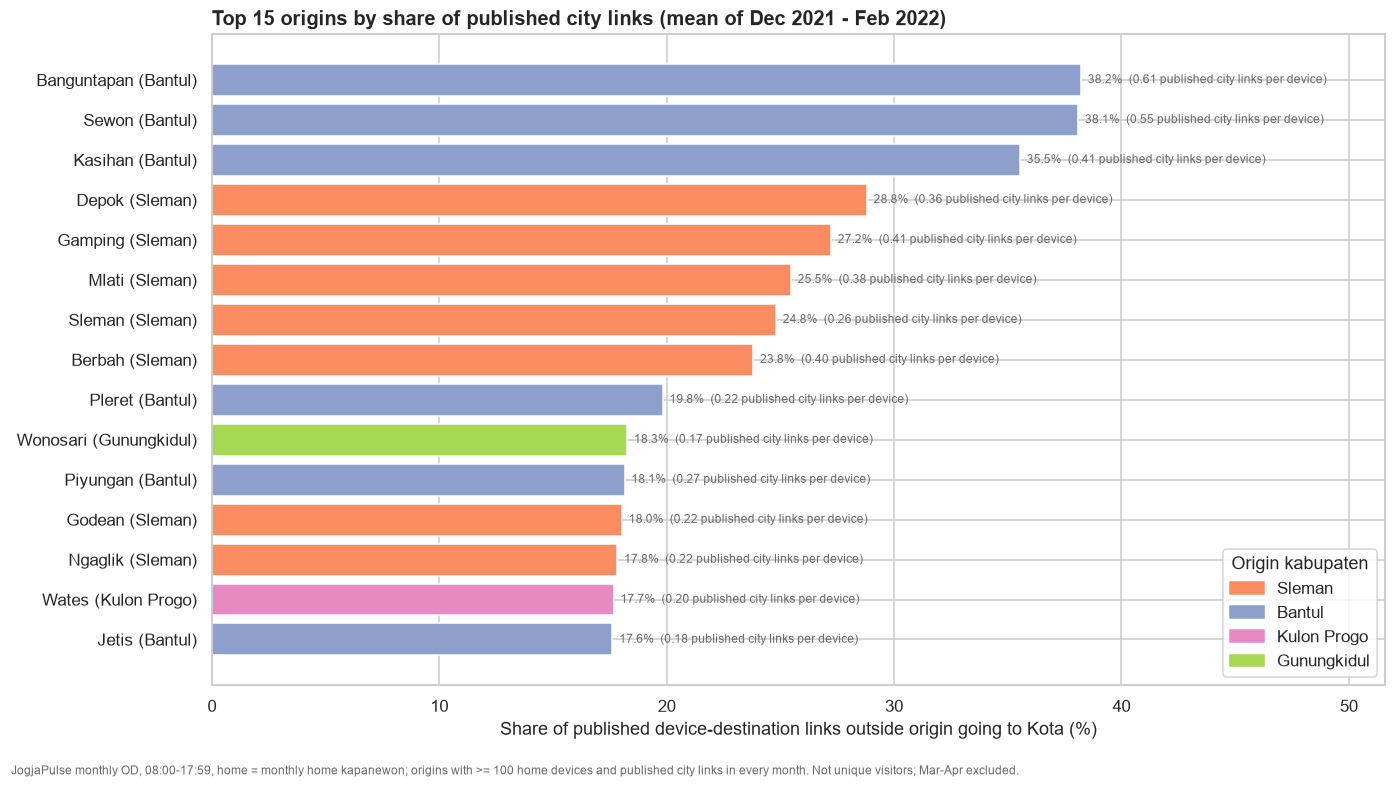

In [4]:
show = res.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.barh(np.arange(len(show)), show["city share (%)"], color=[KAB_COL[k] for k in show.kab_kota])
ax.set_yticks(np.arange(len(show)), [f"{r.kapanewon.title()} ({r.kab_kota.title()})" for r in show.itertuples()])
for i, r in enumerate(show.itertuples()):
    ax.text(r[1] + .3, i, f"{r[1]:.1f}%  ({r[2]:.2f} published city links per device)", va="center", fontsize=8,
            color="dimgrey")
handles = [plt.Rectangle((0, 0), 1, 1, color=KAB_COL[k]) for k in KAB_ORDER[1:]]
ax.legend(handles, [k.title() for k in KAB_ORDER[1:]], loc="lower right", title="Origin kabupaten")
ax.set_xlabel("Share of published device-destination links outside origin going to Kota (%)")
ax.set_xlim(0, show["city share (%)"].max() * 1.35)
ax.set_title(f"Top 15 origins by share of published city links (mean of Dec 2021 - Feb 2022)", loc="left")
fig.text(.01, .01, f"JogjaPulse monthly OD, 08:00-17:59, home = monthly home kapanewon; origins with >= {MIN_HOMED} "
         "home devices and published city links in every month. Not unique visitors; Mar-Apr excluded.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "top_origins")

## 3. Tujuan Kota per asal

Rata-rata proporsi bulanan hanya dihitung jika pasangan terbit pada ketiga bulan.
Sel kosong pada heatmap tetap tidak diketahui. Ringkasan antar-12 asal hanya tersedia
untuk tujuan yang mempunyai semua 12 pasangan lengkap; pembaginya tidak boleh berubah diam-diam.


Mean visit rate to each city kapanewon, averaged over the 12 origins:
dest_code
UMBULHARJO      6.1
GONDOKUSUMAN    4.9
GONDOMANAN      3.8
KOTAGEDE        3.2
JETIS           3.2
MERGANGSAN      2.2
TEGALREJO       NaN
DANUREJAN       NaN
KRATON          NaN
GEDONGTENGEN    NaN
MANTRIJERON     NaN
PAKUALAMAN      NaN
WIROBRAJAN      NaN
NGAMPILAN       NaN


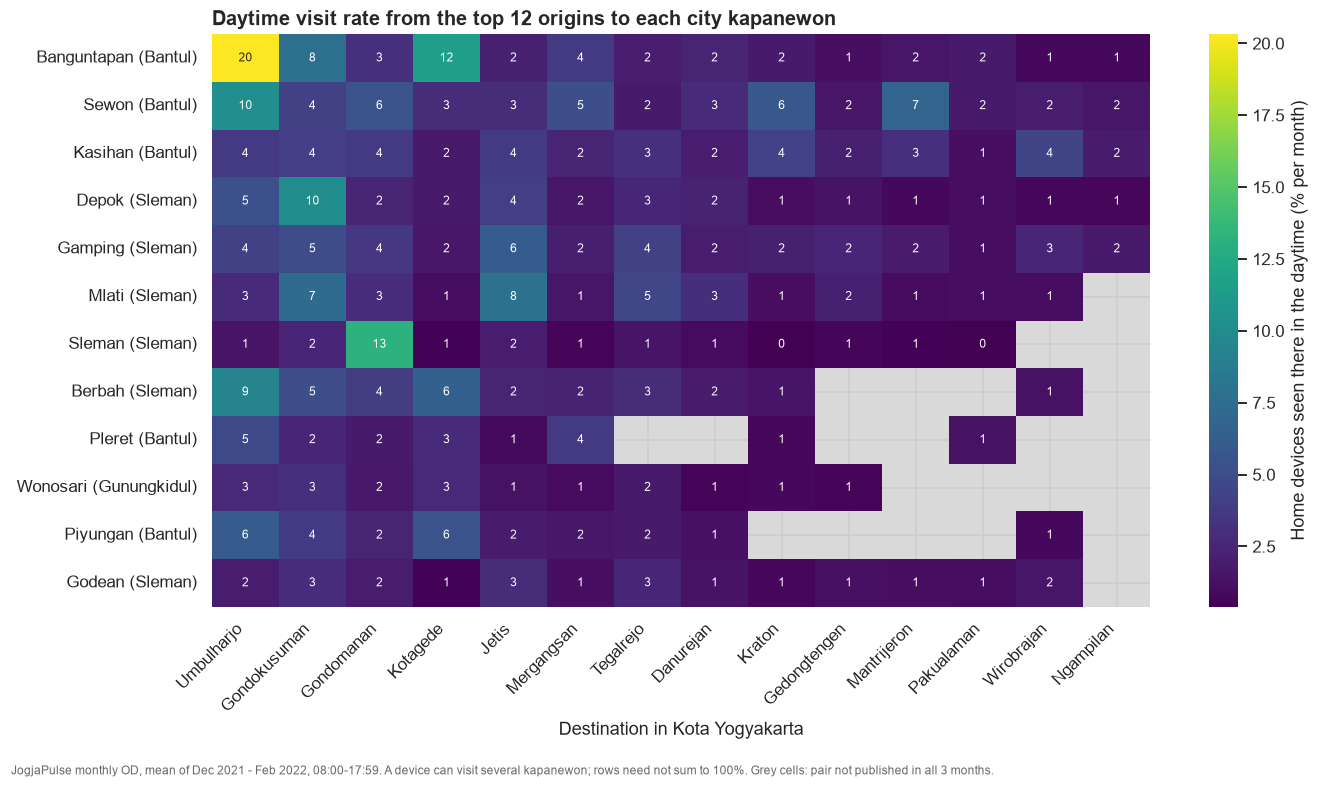

In [5]:
top12 = res.index[:12]
city_destinations = od.loc[od.dest_kab_code.eq(CITY), 'dest_code'].drop_duplicates()
rows = {}
for origin in top12:
    sub = away.loc[away.origin_code.eq(origin) & away.dest_kab_code.eq(CITY)]
    rows[origin] = complete_pair_rates(sub, 'dest_code', OD_GOOD_MONTHS)
pair = pd.DataFrame(rows).T.reindex(index=top12, columns=city_destinations)
dest_names = od.drop_duplicates("dest_code").set_index("dest_code").dest_kapanewon
pair = pair[pair.mean(skipna=False).sort_values(ascending=False).index]
print("Mean visit rate to each city kapanewon, averaged over the 12 origins:")
print((pair.mean(skipna=False) * 100).round(1).rename(dest_names).to_string())

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.set_facecolor("#d9d9d9")
sns.heatmap(pair * 100, ax=ax, cmap="viridis", annot=True, fmt=".0f", annot_kws={"fontsize": 8},
            cbar_kws={"label": "Home devices seen there in the daytime (% per month)"})
ax.set_xticklabels([dest_names[c].title() for c in pair.columns], rotation=45, ha="right")
ax.set_yticklabels([f"{names.kapanewon[c].title()} ({names.kab_kota[c].title()})" for c in pair.index], rotation=0)
ax.set_xlabel("Destination in Kota Yogyakarta")
ax.set_ylabel("")
ax.set_title("Daytime visit rate from the top 12 origins to each city kapanewon", loc="left")
fig.text(.01, .01, "JogjaPulse monthly OD, mean of Dec 2021 - Feb 2022, 08:00-17:59. A device can visit several "
         "kapanewon; rows need not sum to 100%. Grey cells: pair not published in all 3 months.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "origin_destination_heatmap")

## 4. Ringkasan eksplorasi, bukan narasi final

In [6]:
for row in res.head(3).itertuples():
    print(f"{row.kapanewon.title()}: {row[1]:.1f}% of published outside-origin links go to city destinations")
print("Cabupaten medians among eligible complete origins:")
display(kab_tbl)
print("Number of complete three-month origin pairs by destination:")
print(pair.notna().sum().rename(dest_names).to_string())


Banguntapan: 38.2% of published outside-origin links go to city destinations
Sewon: 38.1% of published outside-origin links go to city destinations
Kasihan: 35.5% of published outside-origin links go to city destinations
Cabupaten medians among eligible complete origins:


,city share (%),city visit rate,kapanewon ranked
kab_kota,,,
SLEMAN,15.18,0.19,17
BANTUL,14.00,0.14,16
KULON PROGO,10.59,0.11,11
GUNUNGKIDUL,10.85,0.13,5


Number of complete three-month origin pairs by destination:
dest_code
UMBULHARJO      12
GONDOKUSUMAN    12
GONDOMANAN      12
KOTAGEDE        12
JETIS           12
MERGANGSAN      12
TEGALREJO       11
DANUREJAN       11
KRATON          11
GEDONGTENGEN     9
MANTRIJERON      8
PAKUALAMAN       9
WIROBRAJAN       9
NGAMPILAN        5


Ukuran notebook ini bersifat eksploratif pada hubungan yang diterbitkan. Perangkat yang
sama dapat muncul di beberapa tujuan, dan hubungan yang disembunyikan belum terwakili.
Angka ini bukan pengunjung Kota unik, frekuensi perjalanan atau bukti komuter.

Notebook 07 memakai perbandingan pasangan dengan pembagi asal yang sama, serta proporsi gabungan
berbobot perangkat-bulan. Karena pertanyaannya berbeda, narasi dan grafik final mengikuti notebook 07.
